# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2 (Trang 15-17) - Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và Khả năng sống sót (survived)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


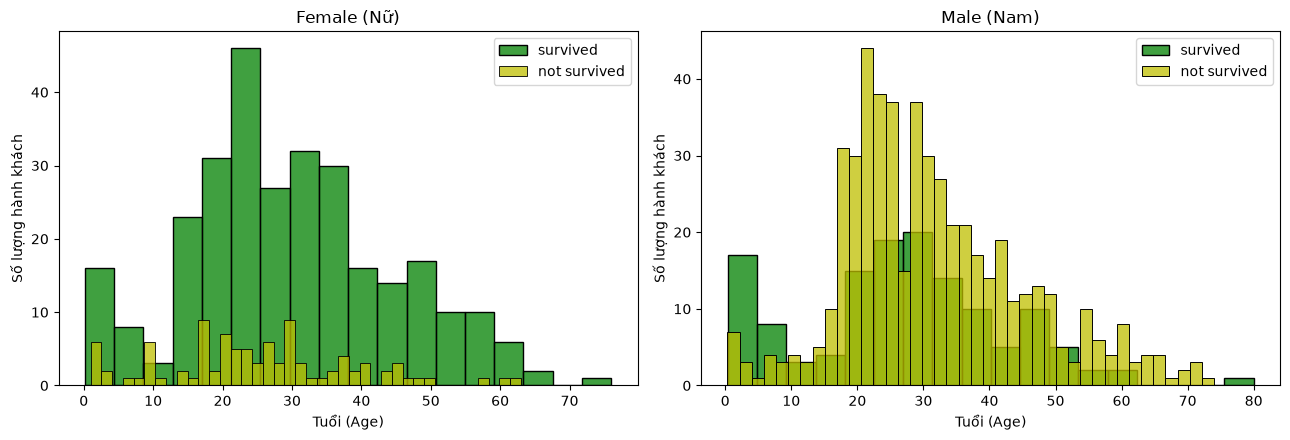

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (15-17) - Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và Sống sót (survived)

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Đọc dữ liệu
def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path),
        os.path.join('..', '..', rel_path),
        os.path.join('datasets', os.path.basename(rel_path)),
        os.path.join('..', 'datasets', os.path.basename(rel_path)),
        os.path.join('..', '..', 'datasets', os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {rel_path}')

csv_path = get_data_path('titanic.csv')
df = pd.read_csv(csv_path, na_values=['?'])
df.columns = df.columns.str.lower()
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

survived = 'survived'
not_survived = 'not survived'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ cho Nữ giới
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female (Nữ)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng hành khách')

# Biểu đồ cho Nam giới
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
ax.set_title('Male (Nam)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng hành khách')

plt.tight_layout()
def get_img_dir(subpath=''):
    for base in ['.', '..', '../..']:
        img_root = os.path.join(base, 'images')
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, 'datasets')) or os.path.exists(os.path.join(base, 'CLAUDE.md'))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join('images', subpath) if subpath else 'images'
    os.makedirs(target, exist_ok=True)
    return target

img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_age_sex_survived.png'), dpi=300, bbox_inches='tight')
